# Laboratorium 3 - Dane obrazowe


## 1. Pobranie zdjęć

In [1]:
import os
import tarfile
import urllib.request
from collections import Counter

import torch
from PIL import Image
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)

URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
ARCHIWUM = "flower_photos.tgz"
ROOT = "dane_lab03_kwiaty"
KLASY = ["daisy", "sunflowers"]
N = 60

if not os.path.exists(ARCHIWUM):
    urllib.request.urlretrieve(URL, ARCHIWUM)

with tarfile.open(ARCHIWUM, "r:gz") as archiwum:
    g = torch.Generator().manual_seed(42)
    for klasa in KLASY:
        os.makedirs(f"{ROOT}/{klasa}", exist_ok=True)
        pliki = sorted(
            [p for p in archiwum.getmembers()
             if p.isfile() and p.name.startswith(f"flower_photos/{klasa}/")
             and p.name.endswith(".jpg")],
            key=lambda p: p.name
        )
        indeksy = torch.randperm(len(pliki), generator=g)[:N].tolist()
        for i in indeksy:
            plik = pliki[i]
            with open(f"{ROOT}/{klasa}/{os.path.basename(plik.name)}", "wb") as f:
                f.write(archiwum.extractfile(plik).read())

    licencja = archiwum.extractfile("flower_photos/LICENSE.txt")
    with open("LICENSE_kwiaty.txt", "wb") as f:
        f.write(licencja.read())

print("Zbiór:", ROOT)
for klasa in KLASY:
    print(klasa, len(os.listdir(f"{ROOT}/{klasa}")))

Zbiór: dane_lab03_kwiaty
daisy 60
sunflowers 60


## 2. Transformacje i ImageFolder

In [2]:
eval_tf = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])

train_tf = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])

ds = datasets.ImageFolder(ROOT, transform=eval_tf)
print("Klasy:", ds.classes)
print("class_to_idx:", ds.class_to_idx)
print("Liczba zdjęć:", len(ds))
print("Liczebność klas:", Counter(ds.targets))

Klasy: ['daisy', 'sunflowers']
class_to_idx: {'daisy': 0, 'sunflowers': 1}
Liczba zdjęć: 120
Liczebność klas: Counter({0: 60, 1: 60})


## 3. Podział 80/20 i DataLoader

In [3]:
g = torch.Generator().manual_seed(42)
perm = torch.randperm(len(ds), generator=g).tolist()
n_val = int(0.2 * len(ds))
val_idx, train_idx = perm[:n_val], perm[n_val:]

train_ds = Subset(datasets.ImageFolder(ROOT, transform=train_tf), train_idx)
val_ds = Subset(datasets.ImageFolder(ROOT, transform=eval_tf), val_idx)

train_dl = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=0)
val_dl = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=0)

print("Trening:", len(train_ds), "zdjęć,", len(train_dl), "paczek")
print("Walidacja:", len(val_ds), "zdjęć,", len(val_dl), "paczek")

Trening: 96 zdjęć, 6 paczek
Walidacja: 24 zdjęć, 1 paczek


## 4. Statystyki danych

In [4]:
tr = Counter(ds.targets[i] for i in train_idx)
va = Counter(ds.targets[i] for i in val_idx)

print(f"{'Klasa':<15} {'Indeks':>7} {'Trening':>9} {'Walidacja':>10} {'Razem':>7}")
for klasa, i in ds.class_to_idx.items():
    print(f"{klasa:<15} {i:>7} {tr[i]:>9} {va[i]:>10} {tr[i] + va[i]:>7}")
print("Liczba klas:", len(ds.classes))
print("Rozmiar tensora:", tuple(train_ds[0][0].shape))
print("class_to_idx:", ds.class_to_idx)

Klasa            Indeks   Trening  Walidacja   Razem
daisy                 0        48         12      60
sunflowers            1        48         12      60
Liczba klas: 2
Rozmiar tensora: (3, 64, 64)
class_to_idx: {'daisy': 0, 'sunflowers': 1}


## 5. Kontrola paczki

In [5]:
xb, yb = next(iter(train_dl))
print("Kształt:", tuple(xb.shape))
print("Typ:", xb.dtype)
print("Minimum:", xb.min().item())
print("Maksimum:", xb.max().item())
print("Etykiety:", yb.tolist())
print("Liczebność klas w paczce:", Counter(yb.tolist()))

assert xb.shape == (16, 3, 64, 64)
assert xb.dtype == torch.float32
assert xb.min().item() >= -1 and xb.max().item() <= 1

Kształt: (16, 3, 64, 64)
Typ: torch.float32
Minimum: -1.0
Maksimum: 1.0
Etykiety: [1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0]
Liczebność klas w paczce: Counter({0: 9, 1: 7})


## 6. Przykłady z paczki

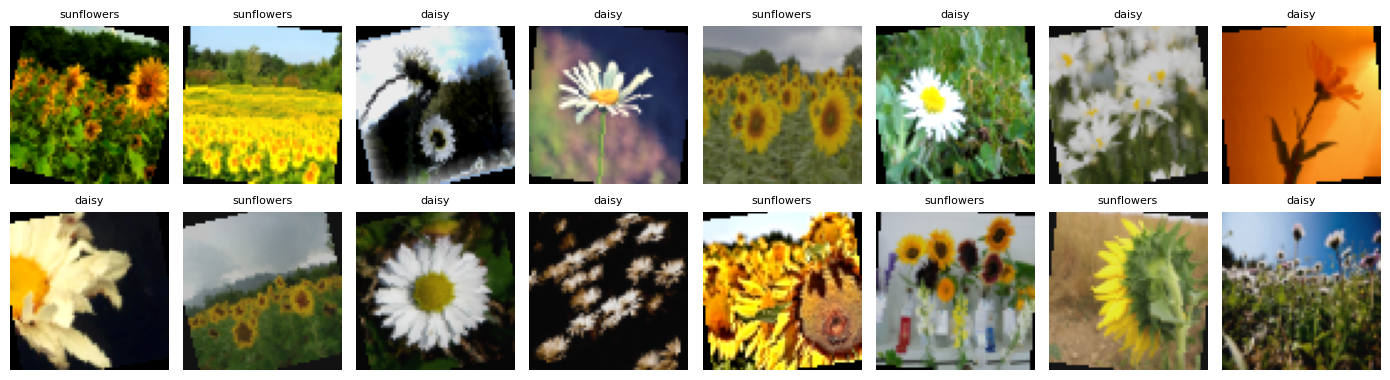

In [6]:
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, label in zip(axes.flat, xb, yb):
    ax.imshow((img * 0.5 + 0.5).permute(1, 2, 0).numpy())
    ax.set_title(ds.classes[int(label)], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.savefig("siatka_zdjec.png", dpi=150)
plt.show()

## 7. Podgląd augmentacji

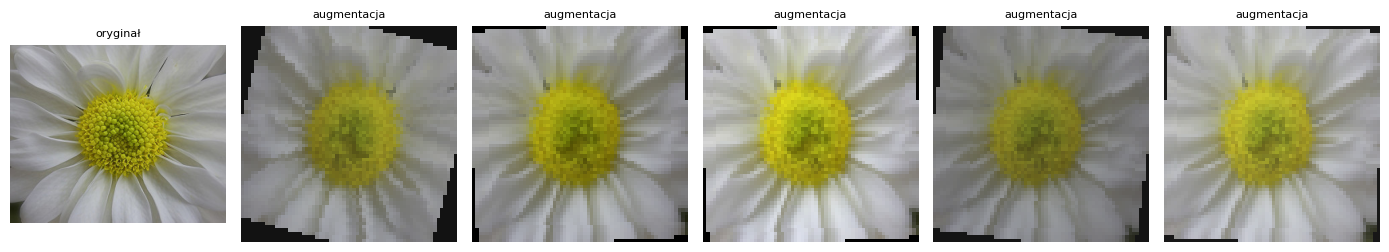

In [7]:
raw = Image.open(ds.samples[0][0]).convert("RGB")
fig, axes = plt.subplots(1, 6, figsize=(14, 2.6))
axes[0].imshow(raw)
axes[0].set_title("oryginał", fontsize=8)
axes[0].axis("off")
for ax in axes[1:]:
    img = train_tf(raw)
    ax.imshow((img * 0.5 + 0.5).permute(1, 2, 0).numpy())
    ax.set_title("augmentacja", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.savefig("augmentacje.png", dpi=150)
plt.show()

## 8. Kontrola walidacji

In [8]:
xv, yv = next(iter(val_dl))
print("Kształt:", tuple(xv.shape))
print("Typ:", xv.dtype)
print("Zakres:", xv.min().item(), "do", xv.max().item())
print("Etykiety:", yv.tolist())

Kształt: (24, 3, 64, 64)
Typ: torch.float32
Zakres: -1.0 do 1.0
Etykiety: [1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0]
